<a href="https://colab.research.google.com/github/Betty-jyw/MMA3001-Occupancy-Prediction/blob/main/notebooks/04_model_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import libraries for model evaluation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from pathlib import Path
from google.colab import drive

# Mount Google Drive
drive.mount("/content/drive")

# Define project directories
project_dir = Path("/content/drive/MyDrive/MMA3001_Project")
data_dir = project_dir / "data" / "processed"
results_dir = project_dir / "results"

results_dir.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully.")
print("Project directory:", project_dir)
print("Processed data directory:", data_dir)
print("Results directory:", results_dir)

Mounted at /content/drive
Libraries imported successfully.
Project directory: /content/drive/MyDrive/MMA3001_Project
Processed data directory: /content/drive/MyDrive/MMA3001_Project/data/processed
Results directory: /content/drive/MyDrive/MMA3001_Project/results


## 1. Load the Processed Dataset

This section loads the feature-engineered occupancy dataset generated in Notebook 02.

The dataset contains historical occupancy features, temporal features, and the binary target variable representing occupancy 30 minutes into the future.

The data will be used to reconstruct the chronological test set for model evaluation.

In [2]:
# Load the feature-engineered occupancy dataset
data_path = data_dir / "occupancy_features.csv"

data = pd.read_csv(
    data_path,
    index_col=0,
    parse_dates=True
)

data = data.sort_index()

print("Dataset loaded successfully.")
print("Dataset shape:", data.shape)

print("\nColumns:")
print(data.columns.tolist())

print("\nTime range:")
print("Start:", data.index.min())
print("End:", data.index.max())

print("\nFirst five rows:")
display(data.head())

Dataset loaded successfully.
Dataset shape: (107059, 11)

Columns:
['current_occupancy', 'target_30min', 'lag_5min', 'lag_10min', 'lag_15min', 'lag_30min', 'hour', 'day_of_week', 'recent_occupancy_rate', 'lag_20min', 'lag_25min']

Time range:
Start: 2023-11-23 21:20:00+00:00
End: 2026-04-22 12:30:00+00:00

First five rows:


,current_occupancy,target_30min,lag_5min,lag_10min,lag_15min,lag_30min,hour,day_of_week,recent_occupancy_rate,lag_20min,lag_25min
collecteddate,,,,,,,,,,,
2023-11-23 21:20:00+00:00,0.0,1.0,0.0,0.0,0.0,0.0,21,3,0.000000,0.0,0.0
2023-11-23 21:25:00+00:00,1.0,1.0,0.0,0.0,0.0,0.0,21,3,0.142857,0.0,0.0
2023-11-23 21:30:00+00:00,1.0,0.0,1.0,0.0,0.0,0.0,21,3,0.285714,0.0,0.0
2023-11-23 21:35:00+00:00,0.0,0.0,1.0,1.0,0.0,0.0,21,3,0.285714,0.0,0.0
2023-11-23 21:40:00+00:00,0.0,0.0,0.0,1.0,1.0,0.0,21,3,0.285714,0.0,0.0


## 2. Chronological Test Set

The dataset is divided chronologically into 80% training data and 20% testing data.

The same test period used in Notebook 03 is retained to ensure consistent model evaluation.

A chronological split is used instead of random sampling to preserve the temporal structure of occupancy observations.

In [3]:
# Recreate the chronological 80/20 split
split_index = int(len(data) * 0.8)

train_data = data.iloc[:split_index].copy()
test_data = data.iloc[split_index:].copy()

# Recalculate temporal features using Melbourne local time
local_time = data.index.tz_convert("Australia/Melbourne")
data["hour"] = local_time.hour
data["day_of_week"] = local_time.dayofweek

# Apply the same local-time correction to the test set
test_local_time = test_data.index.tz_convert("Australia/Melbourne")
test_data["hour"] = test_local_time.hour
test_data["day_of_week"] = test_local_time.dayofweek

# Define test features and labels
feature_columns = [
    "current_occupancy",
    "lag_5min",
    "lag_10min",
    "lag_15min",
    "lag_20min",
    "lag_25min",
    "lag_30min",
    "recent_occupancy_rate",
    "hour",
    "day_of_week"
]

X_test = test_data[feature_columns]
y_test = test_data["target_30min"].astype(int)

print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))

print("\nTest period:")
print("Start:", test_data.index.min())
print("End:", test_data.index.max())

print("\nTest feature shape:", X_test.shape)
print("Test target shape:", y_test.shape)

Training samples: 85647
Testing samples: 21412

Test period:
Start: 2025-09-12 06:05:00+00:00
End: 2026-04-22 12:30:00+00:00

Test feature shape: (21412, 10)
Test target shape: (21412,)


## 3. Load Final Model Predictions

The final model predictions from Notebook 03 will be reused for detailed evaluation.

Reusing the original predictions ensures consistency with the previously reported model performance and avoids unnecessary retraining.

In [5]:
# Check available saved results
print("Files in results directory:\n")

result_files = sorted(results_dir.rglob("*"))

if result_files:
    for file in result_files:
        if file.is_file():
            print(file.relative_to(results_dir))
else:
    print("No saved result files found.")

Files in results directory:

final_model_predictions.csv


In [6]:
# Load final predictions exported from Notebook 03
predictions_path = results_dir / "final_model_predictions.csv"

predictions_df = pd.read_csv(
    predictions_path,
    index_col=0,
    parse_dates=True
)

predictions_df = predictions_df.sort_index()

# Verify prediction data
assert len(predictions_df) == len(y_test), (
    "Prediction count does not match the test set."
)

assert predictions_df.index.equals(y_test.index), (
    "Prediction timestamps do not match the test set."
)

assert np.array_equal(
    predictions_df["actual"].to_numpy(),
    y_test.to_numpy()
), "Actual labels do not match the test set."

assert not predictions_df.isna().any().any(), (
    "Missing values found in predictions."
)

print("Final predictions loaded and verified successfully.")
print("Shape:", predictions_df.shape)

print("\nColumns:")
print(predictions_df.columns.tolist())

display(predictions_df.head())

Final predictions loaded and verified successfully.
Shape: (21412, 4)

Columns:
['actual', 'baseline_pred', 'logistic_pred', 'random_forest_pred']


,actual,baseline_pred,logistic_pred,random_forest_pred
collecteddate,,,,
2025-09-12 06:05:00+00:00,1,1,1,1
2025-09-12 06:10:00+00:00,1,1,1,1
2025-09-12 06:15:00+00:00,1,1,1,1
2025-09-12 06:20:00+00:00,1,0,1,1
2025-09-12 06:25:00+00:00,1,1,1,1


## 4. Model Performance Comparison

The three models are evaluated on the same chronological test set using four classification metrics:

- **Accuracy:** The proportion of correctly classified occupancy states.
- **Precision:** The proportion of predicted occupied states that are actually occupied.
- **Recall:** The proportion of actual occupied states correctly identified.
- **F1-score:** The harmonic mean of precision and recall.

The persistence baseline provides a reference for assessing whether machine learning models improve occupancy prediction.

In [7]:
# Compare final model performance on the test set

model_columns = {
    "Persistence Baseline": "baseline_pred",
    "Logistic Regression": "logistic_pred",
    "Random Forest": "random_forest_pred"
}

actual = predictions_df["actual"]

evaluation_results = []

for model_name, column in model_columns.items():
    predicted = predictions_df[column]

    evaluation_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(actual, predicted),
        "Recall": recall_score(actual, predicted),
        "F1-score": f1_score(actual, predicted)
    })

evaluation_df = pd.DataFrame(evaluation_results)

print("Final Model Performance Comparison:")
display(evaluation_df.round(4))

Final Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1-score
0,Persistence Baseline,0.6740,0.7511,0.7634,0.7572
1,Logistic Regression,0.7168,0.7430,0.8788,0.8052
2,Random Forest,0.6898,0.7359,0.8332,0.7815


## 5. Visual Comparison of Model Performance

A grouped bar chart is used to compare the accuracy, precision, recall, and F1-score of the three models.

This visualisation highlights the differences in classification performance and supports the selection of the most suitable model for 30-minute-ahead occupancy prediction.

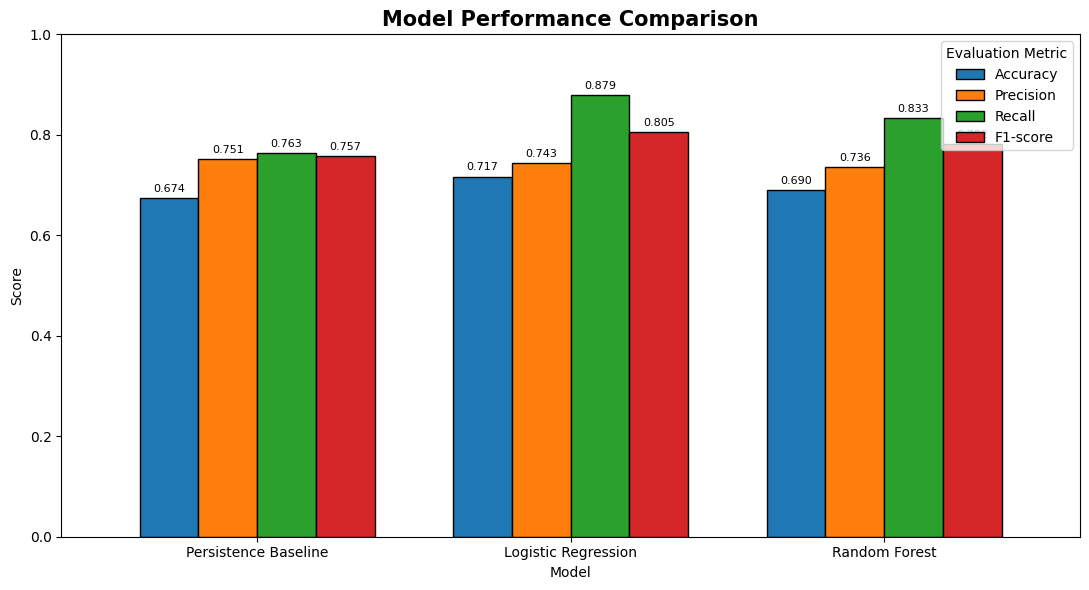

Figure saved to: /content/drive/MyDrive/MMA3001_Project/results/model_performance_comparison.png


In [8]:
# Visualise model performance across four evaluation metrics

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

plot_data = evaluation_df.set_index("Model")[metrics]

ax = plot_data.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75,
    edgecolor="black"
)

ax.set_title(
    "Model Performance Comparison",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.0)

ax.tick_params(axis="x", rotation=0)
ax.legend(title="Evaluation Metric", loc="upper right")

# Display values above each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=8
    )

plt.tight_layout()

# Save figure for the final report
figure_path = results_dir / "model_performance_comparison.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", figure_path)

## 6. Confusion Matrix Analysis

Confusion matrices are used to examine the types of classification errors made by each model.

The four components are:

- **True Negative (TN):** Correctly predicted unoccupied states.
- **False Positive (FP):** Unoccupied states incorrectly predicted as occupied.
- **False Negative (FN):** Occupied states incorrectly predicted as unoccupied.
- **True Positive (TP):** Correctly predicted occupied states.

This analysis helps identify whether the models tend to overpredict or underpredict room occupancy.

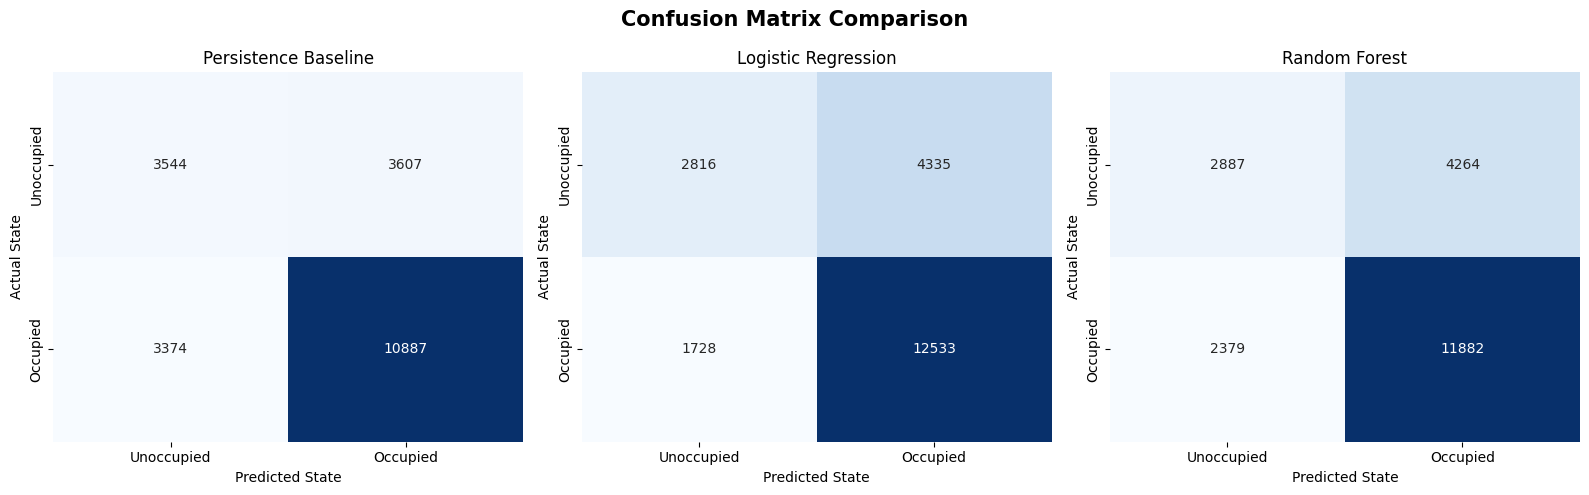

Figure saved to: /content/drive/MyDrive/MMA3001_Project/results/confusion_matrix_comparison.png


In [9]:
# Plot confusion matrices for all three models

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (model_name, column) in zip(
    axes, model_columns.items()
):
    cm = confusion_matrix(
        predictions_df["actual"],
        predictions_df[column],
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Unoccupied", "Occupied"],
        yticklabels=["Unoccupied", "Occupied"],
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted State")
    ax.set_ylabel("Actual State")

plt.suptitle(
    "Confusion Matrix Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

figure_path = results_dir / "confusion_matrix_comparison.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", figure_path)

## 7. Classification Error Analysis

The confusion matrices reveal different error patterns across the three models.

Logistic Regression achieves the lowest number of false negatives, reducing missed occupancy events compared with the persistence baseline. However, this improvement is accompanied by an increase in false positives.

This trade-off is relevant to smart building applications. False negatives may affect occupant comfort if occupancy predictions are used to control building services, while false positives may result in unnecessary energy consumption.

Therefore, model selection should consider not only overall classification performance but also the relative costs of different prediction errors.

In [10]:
# Calculate false positives and false negatives for each model

error_results = []

for model_name, column in model_columns.items():
    cm = confusion_matrix(
        predictions_df["actual"],
        predictions_df[column],
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    error_results.append({
        "Model": model_name,
        "False Positives": fp,
        "False Negatives": fn,
        "Total Errors": fp + fn,
        "False Positive Rate": fp / (fp + tn),
        "False Negative Rate": fn / (fn + tp)
    })

error_df = pd.DataFrame(error_results)

print("Classification Error Comparison:")
display(error_df.round(4))

Classification Error Comparison:


,Model,False Positives,False Negatives,Total Errors,False Positive Rate,False Negative Rate
0,Persistence Baseline,3607,3374,6981,0.5044,0.2366
1,Logistic Regression,4335,1728,6063,0.6062,0.1212
2,Random Forest,4264,2379,6643,0.5963,0.1668


## 8. Visualisation of Classification Errors

A grouped bar chart is used to compare false positive and false negative predictions across the three models.

The visualisation illustrates the trade-off between detecting occupied states and incorrectly predicting occupancy when the room is unoccupied.

This comparison is particularly relevant for smart building applications, where false positives and false negatives may have different operational consequences.

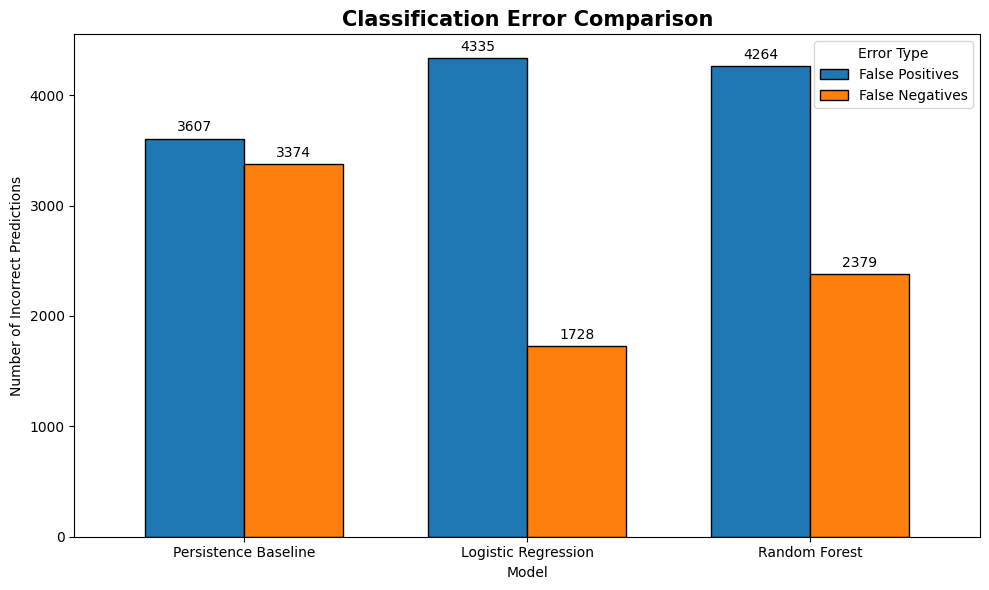

Figure saved to: /content/drive/MyDrive/MMA3001_Project/results/classification_error_comparison.png


In [11]:
# Visualise false positives and false negatives

error_plot = error_df.set_index("Model")[
    ["False Positives", "False Negatives"]
]

ax = error_plot.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.7,
    edgecolor="black"
)

ax.set_title(
    "Classification Error Comparison",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Model")
ax.set_ylabel("Number of Incorrect Predictions")

ax.tick_params(axis="x", rotation=0)
ax.legend(title="Error Type")

# Add numerical labels above the bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%d",
        padding=3
    )

plt.tight_layout()

# Save figure
figure_path = results_dir / "classification_error_comparison.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", figure_path)

## 9. Occupancy Prediction Bias Analysis

This section investigates whether the models systematically overpredict or underpredict room occupancy.

The actual occupancy rate is compared with the predicted occupancy rate of each model.

Prediction bias is calculated as:

Prediction Bias = Predicted Occupancy Rate − Actual Occupancy Rate

A positive value indicates that the model predicts occupied states more frequently than observed, while a negative value indicates underprediction.

This analysis helps explain the balance between false positive and false negative errors.

In [12]:
# Calculate actual occupancy rate
actual_occupancy_rate = predictions_df["actual"].mean()

# Calculate predicted occupancy rates and biases
bias_results = []

for model_name, column in model_columns.items():
    predicted_rate = predictions_df[column].mean()

    bias_results.append({
        "Model": model_name,
        "Actual Occupancy Rate": actual_occupancy_rate,
        "Predicted Occupancy Rate": predicted_rate,
        "Prediction Bias": predicted_rate - actual_occupancy_rate
    })

bias_df = pd.DataFrame(bias_results)

print("Occupancy Prediction Bias Comparison:")
display(bias_df.round(4))

Occupancy Prediction Bias Comparison:


,Model,Actual Occupancy Rate,Predicted Occupancy Rate,Prediction Bias
0,Persistence Baseline,0.666,0.6769,0.0109
1,Logistic Regression,0.666,0.7878,0.1218
2,Random Forest,0.666,0.7541,0.0880


## 10. Visualisation of Occupancy Prediction Bias

This section compares the actual occupancy rate with the predicted occupancy rates of the three models.

The visualisation illustrates systematic differences between observed and predicted occupancy frequencies.

Although Logistic Regression achieves the highest F1-score, it predicts occupied states more frequently than observed. This highlights the importance of considering prediction bias alongside conventional classification metrics.

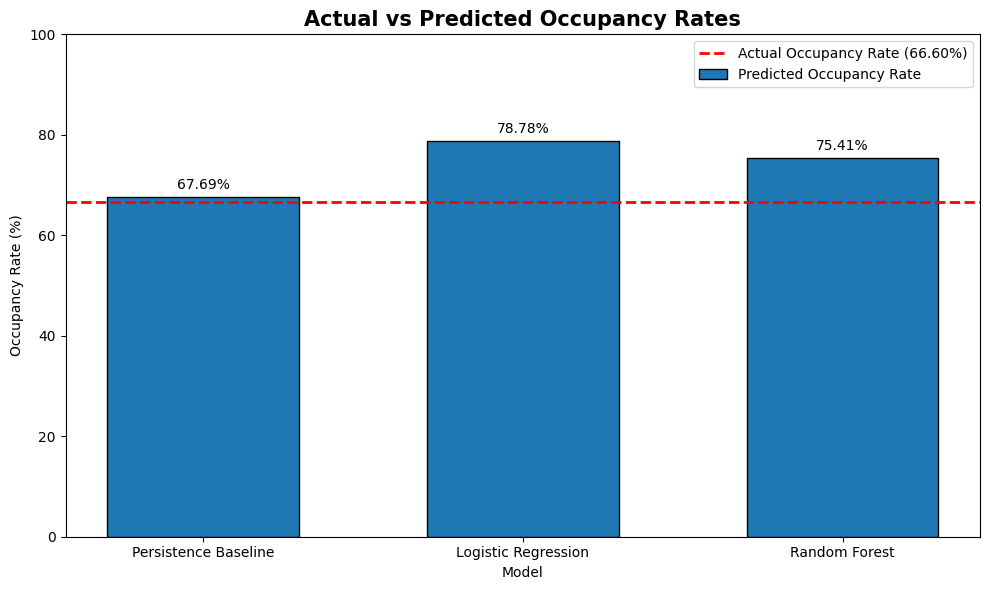

Figure saved to: /content/drive/MyDrive/MMA3001_Project/results/occupancy_prediction_bias.png


In [13]:
# Visualise actual and predicted occupancy rates

fig, ax = plt.subplots(figsize=(10, 6))

models = bias_df["Model"]
predicted_rates = bias_df["Predicted Occupancy Rate"] * 100
actual_rate = actual_occupancy_rate * 100

bars = ax.bar(
    models,
    predicted_rates,
    width=0.6,
    edgecolor="black",
    label="Predicted Occupancy Rate"
)

# Add reference line for actual occupancy
ax.axhline(
    y=actual_rate,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Actual Occupancy Rate ({actual_rate:.2f}%)"
)

# Add values above bars
for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.2f}%",
        ha="center",
        va="bottom"
    )

ax.set_title(
    "Actual vs Predicted Occupancy Rates",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Model")
ax.set_ylabel("Occupancy Rate (%)")
ax.set_ylim(0, 100)
ax.legend()

plt.tight_layout()

# Save figure
figure_path = results_dir / "occupancy_prediction_bias.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", figure_path)

## 11. Monthly Model Performance Analysis

This section evaluates how model performance changes across different months of the test period.

Monthly accuracy and F1-score are calculated separately for the persistence baseline, Logistic Regression, and Random Forest models.

This analysis helps identify potential temporal variation in prediction performance and assess whether the models remain consistent over time.

Months with fewer observations should be interpreted cautiously because their evaluation metrics may be less representative.

In [14]:
# Calculate monthly classification performance

monthly_data = predictions_df.copy()

# Convert UTC timestamps to Melbourne local time
monthly_data.index = monthly_data.index.tz_convert(
    "Australia/Melbourne"
)

monthly_data["month"] = monthly_data.index.strftime("%Y-%m")

monthly_results = []

for month, group in monthly_data.groupby("month"):
    for model_name, column in model_columns.items():

        monthly_results.append({
            "Month": month,
            "Model": model_name,
            "Samples": len(group),
            "Accuracy": accuracy_score(
                group["actual"],
                group[column]
            ),
            "F1-score": f1_score(
                group["actual"],
                group[column],
                zero_division=0
            )
        })

monthly_df = pd.DataFrame(monthly_results)

print("Monthly Model Performance:")
display(monthly_df.round(4))

Monthly Model Performance:


,Month,Model,Samples,Accuracy,F1-score
0,2025-09,Persistence Baseline,1897,0.6927,0.7802
1,2025-09,Logistic Regression,1897,0.7364,0.8257
2,2025-09,Random Forest,1897,0.7180,0.8093
3,2025-10,Persistence Baseline,4044,0.6761,0.7698
4,2025-10,Logistic Regression,4044,0.7295,0.8227
5,2025-10,Random Forest,4044,0.6963,0.7931
6,2025-11,Persistence Baseline,3295,0.6455,0.6887
7,2025-11,Logistic Regression,3295,0.6753,0.7375
8,2025-11,Random Forest,3295,0.6580,0.7203
9,2025-12,Persistence Baseline,2077,0.6052,0.6563


## 12. Temporal Stability of Model Performance

Monthly accuracy and F1-score are visualised to examine changes in prediction performance throughout the test period.

This analysis evaluates the temporal consistency of the three models and identifies periods of relatively strong or weak performance.

Variations in monthly performance may reflect changes in occupancy patterns, class distributions, or other temporal factors. Further investigation would be required to determine the underlying causes.

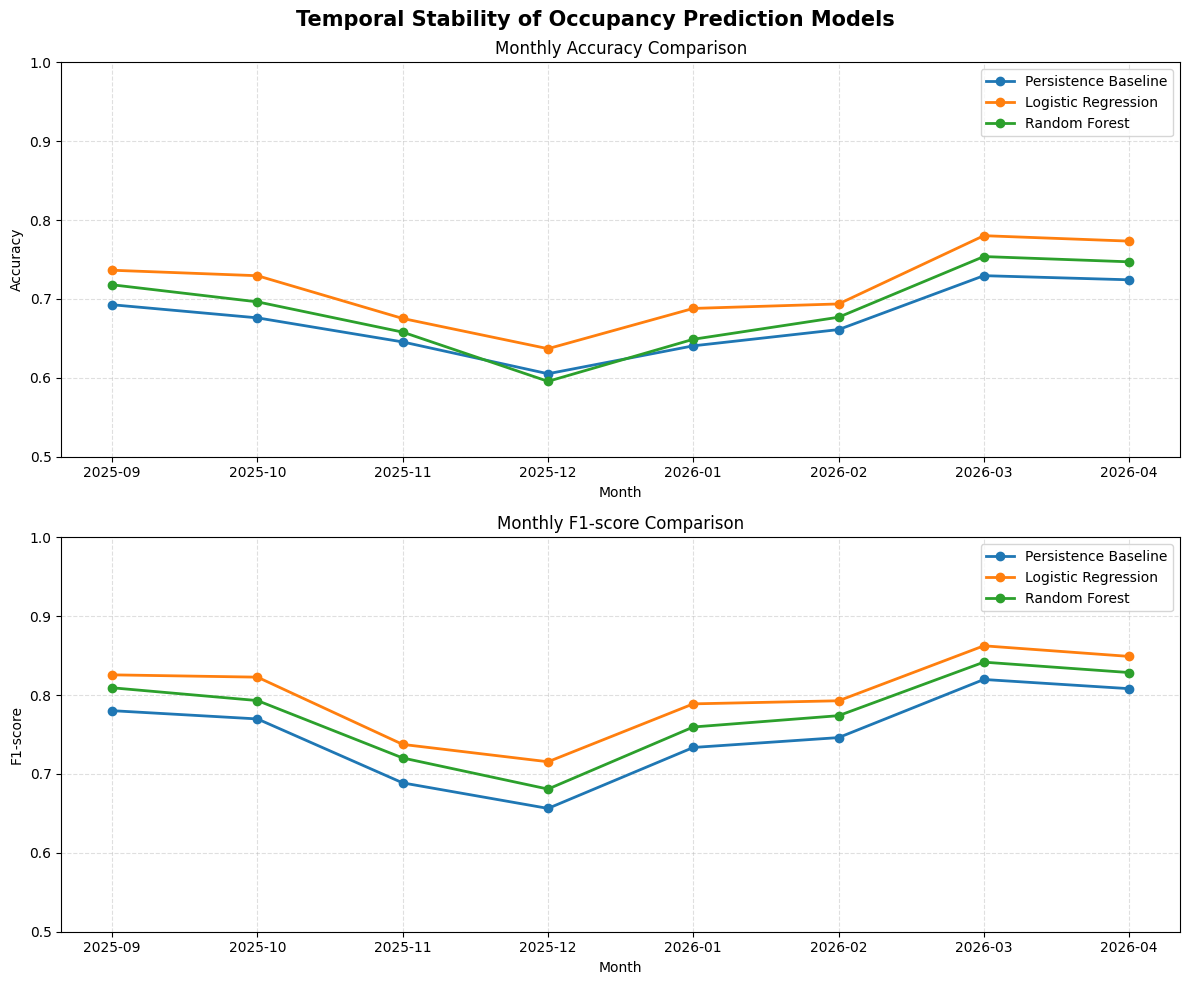

Figure saved to: /content/drive/MyDrive/MMA3001_Project/results/monthly_model_performance.png


In [15]:
# Visualise monthly accuracy and F1-score

fig, axes = plt.subplots(2, 1, figsize=(12, 10))

metrics = ["Accuracy", "F1-score"]

for ax, metric in zip(axes, metrics):

    monthly_pivot = monthly_df.pivot(
        index="Month",
        columns="Model",
        values=metric
    )

    for model in model_columns.keys():
        ax.plot(
            monthly_pivot.index,
            monthly_pivot[model],
            marker="o",
            linewidth=2,
            label=model
        )

    ax.set_title(f"Monthly {metric} Comparison")
    ax.set_xlabel("Month")
    ax.set_ylabel(metric)
    ax.set_ylim(0.5, 1.0)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend()

plt.suptitle(
    "Temporal Stability of Occupancy Prediction Models",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

figure_path = results_dir / "monthly_model_performance.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", figure_path)

## 13. Monthly Occupancy Distribution Analysis

This section examines changes in the actual occupancy rate across the test period.

The monthly occupancy rate is calculated as the proportion of observations labelled as occupied.

Comparing monthly occupancy distributions with model performance may help explain temporal variations in accuracy and F1-score.

However, changes in occupancy prevalence alone do not establish the causes of model performance differences.

In [16]:
# Calculate monthly actual occupancy rates

monthly_occupancy = (
    monthly_data.groupby("month")
    .agg(
        Samples=("actual", "size"),
        Occupied_Samples=("actual", "sum"),
        Actual_Occupancy_Rate=("actual", "mean")
    )
    .reset_index()
    .rename(columns={"month": "Month"})
)

monthly_occupancy["Unoccupied_Samples"] = (
    monthly_occupancy["Samples"]
    - monthly_occupancy["Occupied_Samples"]
)

monthly_occupancy["Actual_Occupancy_Percentage"] = (
    monthly_occupancy["Actual_Occupancy_Rate"] * 100
)

print("Monthly Actual Occupancy Distribution:")

display(monthly_occupancy.round(4))

Monthly Actual Occupancy Distribution:


,Month,Samples,Occupied_Samples,Actual_Occupancy_Rate,Unoccupied_Samples,Actual_Occupancy_Percentage
0,2025-09,1897,1303,0.6869,594,68.6874
1,2025-10,4044,2822,0.6978,1222,69.7824
2,2025-11,3295,1855,0.5630,1440,56.2974
3,2025-12,2077,1178,0.5672,899,56.7164
4,2026-01,2045,1379,0.6743,666,67.4328
5,2026-02,2553,1692,0.6627,861,66.2750
6,2026-03,3176,2366,0.7450,810,74.4962
7,2026-04,2325,1666,0.7166,659,71.6559


## 14. Relationship Between Occupancy Distribution and Model Performance

This section compares the monthly actual occupancy rate with the F1-score of Logistic Regression, the best-performing model.

The objective is to investigate whether changes in occupancy prevalence are associated with variations in prediction performance.

Since F1-score depends partly on class prevalence, any observed association should not be interpreted as evidence of causation.

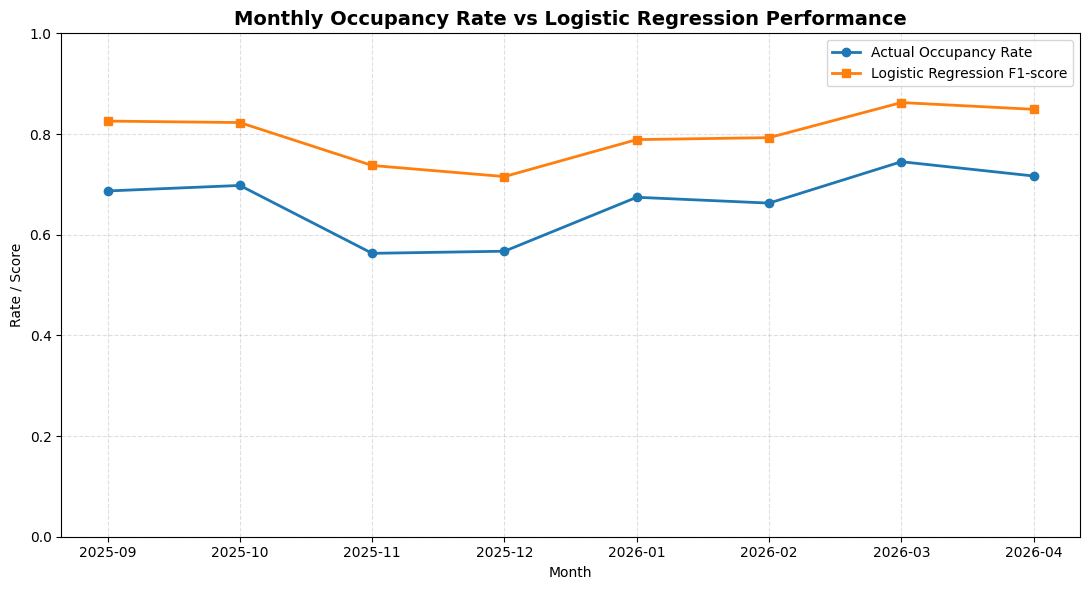

Pearson correlation: 0.9763
Figure saved to: /content/drive/MyDrive/MMA3001_Project/results/occupancy_rate_vs_f1.png


In [17]:
# Compare monthly occupancy rate with Logistic Regression F1-score

logistic_monthly = monthly_df[
    monthly_df["Model"] == "Logistic Regression"
][["Month", "F1-score"]].copy()

comparison_df = monthly_occupancy[
    ["Month", "Actual_Occupancy_Rate"]
].merge(
    logistic_monthly,
    on="Month",
    how="inner"
)

# Calculate descriptive correlation
correlation = comparison_df[
    "Actual_Occupancy_Rate"
].corr(comparison_df["F1-score"])

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    comparison_df["Month"],
    comparison_df["Actual_Occupancy_Rate"],
    marker="o",
    linewidth=2,
    label="Actual Occupancy Rate"
)

ax.plot(
    comparison_df["Month"],
    comparison_df["F1-score"],
    marker="s",
    linewidth=2,
    label="Logistic Regression F1-score"
)

ax.set_title(
    "Monthly Occupancy Rate vs Logistic Regression Performance",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Month")
ax.set_ylabel("Rate / Score")
ax.set_ylim(0, 1)

ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()

plt.tight_layout()

figure_path = results_dir / "occupancy_rate_vs_f1.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Pearson correlation:", round(correlation, 4))
print("Figure saved to:", figure_path)

### Interpretation

The monthly actual occupancy rate and Logistic Regression F1-score showed a strong positive correlation (r = 0.9763) across the eight test months.

Months with lower occupancy rates, particularly November and December 2025, generally showed lower F1-scores. In contrast, March 2026 had both the highest occupancy rate (74.50%) and the highest F1-score (0.8625).

This association suggests that model performance varies with the observed occupancy distribution. However, the result is descriptive rather than causal, because F1-score is sensitive to class prevalence and only eight monthly observations were analysed.

In [18]:
# Calculate monthly prediction bias for each model

monthly_bias_results = []

for month, group in monthly_data.groupby("month"):
    actual_rate = group["actual"].mean()

    for model_name, column in model_columns.items():
        predicted_rate = group[column].mean()

        monthly_bias_results.append({
            "Month": month,
            "Model": model_name,
            "Samples": len(group),
            "Actual Rate": actual_rate,
            "Predicted Rate": predicted_rate,
            "Bias (pp)": (predicted_rate - actual_rate) * 100
        })

monthly_bias_df = pd.DataFrame(monthly_bias_results)

print("Monthly Occupancy Prediction Bias:")
display(monthly_bias_df.round(4))

Monthly Occupancy Prediction Bias:


,Month,Model,Samples,Actual Rate,Predicted Rate,Bias (pp)
0,2025-09,Persistence Baseline,1897,0.6869,0.7116,2.4776
1,2025-09,Logistic Regression,1897,0.6869,0.8250,13.8113
2,2025-09,Random Forest,1897,0.6869,0.7918,10.4902
3,2025-10,Persistence Baseline,4044,0.6978,0.7092,1.1375
4,2025-10,Logistic Regression,4044,0.6978,0.8284,13.0564
5,2025-10,Random Forest,4044,0.6978,0.7695,7.1711
6,2025-11,Persistence Baseline,3295,0.5630,0.5757,1.2747
7,2025-11,Logistic Regression,3295,0.5630,0.6741,11.1077
8,2025-11,Random Forest,3295,0.5630,0.6598,9.6813
9,2025-12,Persistence Baseline,2077,0.5672,0.5816,1.4444


## 15. Temporal Variation in Prediction Bias

Monthly prediction bias is compared across the three models to assess whether occupancy overprediction remains consistent over time.

Positive bias indicates that the predicted proportion of occupied observations exceeds the actual proportion.

This analysis complements the monthly performance evaluation by highlighting systematic differences between predicted and observed occupancy frequencies.

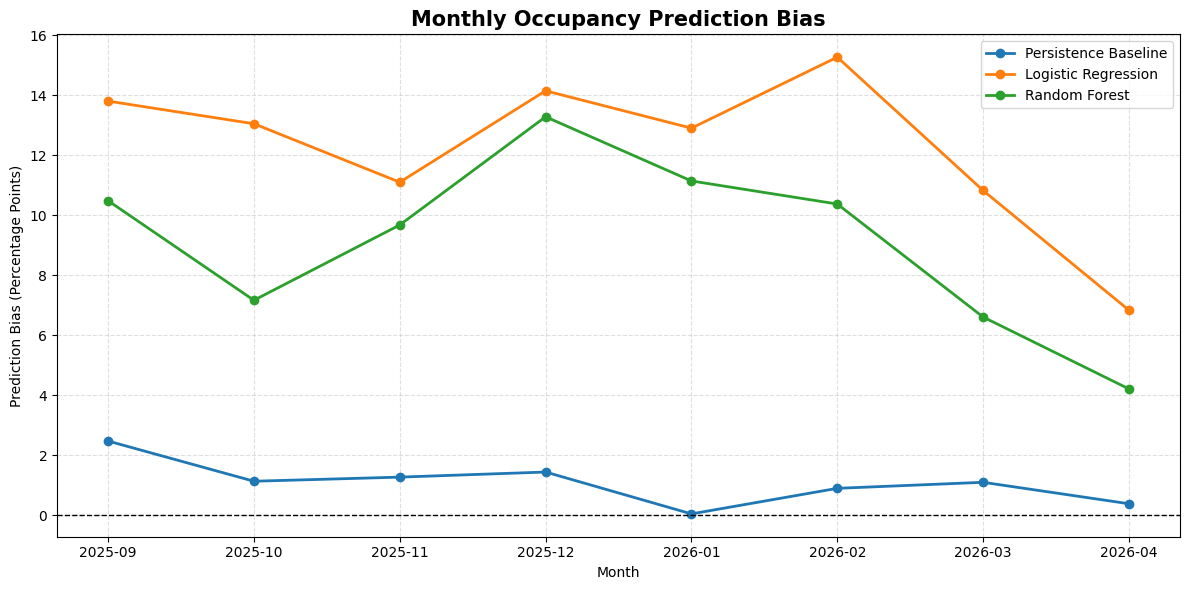

Figure saved to: /content/drive/MyDrive/MMA3001_Project/results/monthly_prediction_bias.png


In [19]:
# Visualise monthly occupancy prediction bias

monthly_bias_pivot = monthly_bias_df.pivot(
    index="Month",
    columns="Model",
    values="Bias (pp)"
)

fig, ax = plt.subplots(figsize=(12, 6))

for model_name in model_columns.keys():
    ax.plot(
        monthly_bias_pivot.index,
        monthly_bias_pivot[model_name],
        marker="o",
        linewidth=2,
        label=model_name
    )

# Reference line indicating no prediction bias
ax.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Monthly Occupancy Prediction Bias",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Month")
ax.set_ylabel("Prediction Bias (Percentage Points)")
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()

plt.tight_layout()

# Save figure for the final report
figure_path = results_dir / "monthly_prediction_bias.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", figure_path)

## 16. Final Evaluation Summary

### 16.1 Overall Model Performance

Three models were evaluated for 30-minute-ahead room occupancy prediction: Persistence Baseline, Logistic Regression, and Random Forest.

Logistic Regression achieved the best overall classification performance, with an accuracy of 0.7168, precision of 0.7430, recall of 0.8788, and F1-score of 0.8052.

Random Forest achieved an F1-score of 0.7815, while the Persistence Baseline achieved an F1-score of 0.7572.

These results demonstrate that both machine learning models improved F1-score compared with the persistence baseline, with Logistic Regression providing the strongest overall performance.

### 16.2 Classification Errors

Logistic Regression produced the fewest false negatives (1,728), compared with 3,374 for the Persistence Baseline and 2,379 for Random Forest.

However, Logistic Regression also produced the most false positives (4,335), indicating a tendency to predict occupied states more frequently.

This trade-off may be relevant for smart building management, where missed occupancy events and unnecessary activation of building services may have different operational consequences.

### 16.3 Occupancy Prediction Bias

The actual occupancy rate in the test dataset was approximately 66.60%.

Logistic Regression predicted an occupancy rate of 78.78%, resulting in a positive bias of 12.18 percentage points.

Random Forest showed a positive bias of 8.80 percentage points, while the Persistence Baseline had a smaller bias of 1.09 percentage points.

These results indicate that the model with the highest F1-score does not necessarily provide the most accurate estimate of overall occupancy frequency.

### 16.4 Temporal Stability

Monthly evaluation revealed variations in model performance between September 2025 and April 2026.

Logistic Regression achieved the highest monthly F1-score in March 2026 (0.8625) and the lowest in December 2025 (0.7155).

The monthly actual occupancy rate and Logistic Regression F1-score were strongly positively correlated (r = 0.9763).

However, this relationship should be interpreted cautiously because F1-score is affected by class prevalence, and the analysis includes only eight monthly observations.

Monthly prediction bias analysis also showed that Logistic Regression consistently overestimated occupancy frequency throughout the test period.

### 16.5 Model Selection and Limitations

Based on the evaluation results, Logistic Regression was selected as the preferred model for 30-minute-ahead occupancy classification because it achieved the highest accuracy, recall, and F1-score.

Nevertheless, several limitations remain:

- The analysis was conducted using data from a single selected room.
- Environmental sensor measurements were not incorporated because a reliable mapping to the selected occupancy space could not be established.
- The models exhibited relatively high false positive rates.
- Logistic Regression systematically overpredicted occupied states.
- Model performance varied across different months.
- The evaluation was retrospective and does not demonstrate performance in a live building control system.

Future improvements could include collecting additional room-specific environmental data, evaluating more rooms, improving probability calibration, and investigating alternative classification thresholds using validation data.

### 16.6 Conclusion

The results demonstrate that historical occupancy information can support short-term room occupancy prediction.

Logistic Regression outperformed the Persistence Baseline and Random Forest in overall classification performance, achieving an F1-score of 0.8052 on the chronological test set.

However, the observed prediction bias and temporal performance variation highlight the importance of evaluating multiple performance measures before applying occupancy predictions in practical smart building systems.

In [20]:
# Verify all expected evaluation figures

expected_files = [
    "final_model_predictions.csv",
    "model_performance_comparison.png",
    "confusion_matrix_comparison.png",
    "classification_error_comparison.png",
    "occupancy_prediction_bias.png",
    "monthly_model_performance.png",
    "occupancy_rate_vs_f1.png",
    "monthly_prediction_bias.png"
]

print("Notebook 04 - Output File Verification\n")

missing_files = []

for filename in expected_files:
    file_path = results_dir / filename

    if file_path.is_file():
        print(f"PASS: {filename}")
    else:
        print(f"MISSING: {filename}")
        missing_files.append(filename)

print(f"\nFiles verified: {len(expected_files) - len(missing_files)}/{len(expected_files)}")

if not missing_files:
    print("All expected evaluation files are available.")
else:
    print("Some evaluation files need to be checked.")

Notebook 04 - Output File Verification

PASS: final_model_predictions.csv
PASS: model_performance_comparison.png
PASS: confusion_matrix_comparison.png
PASS: classification_error_comparison.png
PASS: occupancy_prediction_bias.png
PASS: monthly_model_performance.png
PASS: occupancy_rate_vs_f1.png
PASS: monthly_prediction_bias.png

Files verified: 8/8
All expected evaluation files are available.


In [21]:
from pathlib import Path
import shutil

# Source notebook in Google Colab
source_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/04_model_evaluation.ipynb"
)

# Destination inside the project
destination_path = Path(
    "/content/drive/MyDrive/MMA3001_Project/notebooks/04_model_evaluation.ipynb"
)

destination_path.parent.mkdir(parents=True, exist_ok=True)

if source_path.exists():
    shutil.copy2(source_path, destination_path)

    print("Notebook copied successfully.")
    print("Destination:", destination_path)
else:
    print("Source notebook not found.")
    print("Please check the notebook filename in Google Drive.")

Notebook copied successfully.
Destination: /content/drive/MyDrive/MMA3001_Project/notebooks/04_model_evaluation.ipynb
